# Tabular — Regresi
**Kapan dipakai:** data tabel (CSV), dan kita diminta menebak ANGKA untuk tiap baris test.
Contoh: harga rumah, jumlah penjualan, nilai klaim.

**Langkah:**
1. Baca data, lihat sebaran target.
2. Bagi train menjadi train dan validasi.
3. Siapkan kolom, latih model, ukur RMSE/MAE/R2 di validasi.
4. Latih ulang di semua data train, tebak test, simpan submission.

**Data demo:** Diamonds (target `price`). Ganti path dan nama kolom di sel Konfigurasi.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import BayesianRidge, ElasticNet, HuberRegressor, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular/regression"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/diamonds_train.csv"
TEST_CSV = f"{DATA_FOLDER}/diamonds_test.csv"

TARGET = "price"                                       # kolom angka yang ditebak
NUM_COLS = ["carat", "depth", "table", "x", "y", "z"]  # kolom angka
CAT_COLS = ["cut", "color", "clarity"]                 # kolom kategori (teks)
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train.isna().sum())
train.head()

train: (4800, 11) | test: (1200, 10)
id         0
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


,id,carat,cut,color,clarity,depth,table,price,x,y,z
0,3898,0.37,Premium,F,VS2,61.0,58.0,957,4.63,4.61,2.82
1,5629,0.40,Very Good,D,VS2,63.5,55.0,952,4.69,4.66,2.97
2,1757,0.31,Premium,G,IF,61.0,59.0,988,4.36,4.33,2.65
3,2347,0.31,Ideal,E,SI1,63.0,57.0,698,4.32,4.29,2.71
4,2997,0.54,Ideal,G,VS1,61.0,57.0,1957,5.25,5.28,3.21


## EDA
- Sebaran target: kalau sangat miring ke kanan (banyak kecil, sedikit sangat besar),
  pertimbangkan `np.log1p(target)`.
- Korelasi kolom angka dengan target: makin jauh dari 0, makin berpengaruh.

count     4800.000000
mean      3894.332292
std       3928.386503
min        351.000000
25%        945.000000
50%       2382.000000
75%       5305.250000
max      18787.000000
Name: price, dtype: float64


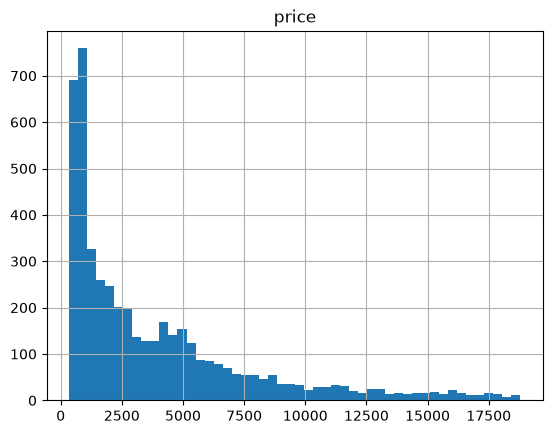

depth   -0.027081
table    0.143909
z        0.868104
x        0.876759
y        0.878200
carat    0.918384
price    1.000000
Name: price, dtype: float64


In [4]:
print(train[TARGET].describe())
train[TARGET].hist(bins=50)
plt.title(TARGET)
plt.show()

correlation = train[NUM_COLS + [TARGET]].corr()
print(correlation[TARGET].sort_values())

## Split train / validasi

In [5]:
X = train[NUM_COLS + CAT_COLS]
y = train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("train:", X_train.shape, "| validasi:", X_val.shape)

train: (3840, 9) | validasi: (960, 9)


## Model
`preprocess`: kolom angka diisi median + StandardScaler, kolom kategori diisi nilai terbanyak
+ OneHot. Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
num_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore"))
preprocess = ColumnTransformer([
    ("num", num_steps, NUM_COLS),
    ("cat", cat_steps, CAT_COLS),
])

model = LGBMRegressor(n_estimators=1000, learning_rate=0.03, random_state=SEED, verbose=-1)
# model = Ridge(alpha=1.0)                                  # regresi linear + penalti
# model = Lasso(alpha=1.0)
# model = ElasticNet(alpha=0.1, l1_ratio=0.5)
# model = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
# model = ExtraTreesRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
# model = HistGradientBoostingRegressor(random_state=SEED)
# model = XGBRegressor(n_estimators=1000, learning_rate=0.03, random_state=SEED)
# model = CatBoostRegressor(iterations=1000, random_seed=SEED, verbose=0)
# model = KNeighborsRegressor(n_neighbors=10)
# model = DecisionTreeRegressor(max_depth=10, random_state=SEED)
# model = GradientBoostingRegressor(random_state=SEED)
# model = AdaBoostRegressor(n_estimators=300, random_state=SEED)
# model = BayesianRidge()
# model = HuberRegressor(max_iter=1000)                     # tahan terhadap outlier
# model = LinearSVR(C=1.0, max_iter=10000, random_state=SEED)
# model = MLPRegressor(hidden_layer_sizes=(64,), max_iter=500, random_state=SEED)

pipe = make_pipeline(preprocess, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('lgbmregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['carat','depth','table',...,'cut','color','clarity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis conc

## Evaluasi di validasi
RMSE dan MAE dalam satuan target (makin kecil makin bagus). R2: 1.0 = sempurna.
Gambar: titik makin dekat garis diagonal, makin tepat.

RMSE: 828.1
MAE : 336.79
R2  : 0.9561


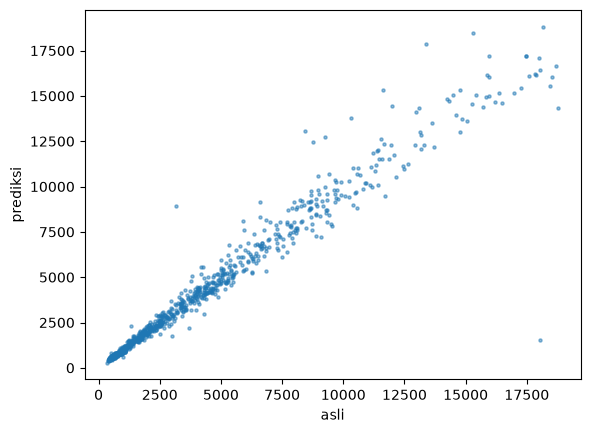

In [7]:
val_predictions = pipe.predict(X_val)
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, val_predictions)), 2))
print("MAE :", round(mean_absolute_error(y_val, val_predictions), 2))
print("R2  :", round(r2_score(y_val, val_predictions), 4))

plt.scatter(y_val, val_predictions, s=5, alpha=0.5)
plt.xlabel("asli")
plt.ylabel("prediksi")
plt.show()

## Latih ulang di semua data + submission

In [8]:
pipe.fit(X, y)
predictions = pipe.predict(test[NUM_COLS + CAT_COLS])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["price"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,price
0,1783,4264.401670
1,3918,5243.829643
2,222,2840.440400
3,2136,15775.751777
4,5225,888.786738
